## Case Study 1: Dataset Downloading and Loading

### Objective
The objective of this initial stage is to programmatically and securely download the legal citation text classification dataset from Kaggle (`shivamb/legal-citation-text-classification`) using `kagglehub`.

### Methodology & Implementation
1. **Automated Fetching**: By utilizing `kagglehub.dataset_download`, we ensure that the latest version of the dataset is cached locally without requiring manual web downloads.
2. **Directory Traversal**: We dynamically scan the downloaded path to locate any `.csv` files using `os.walk` to make the path-resolution environment-agnostic.
3. **Pandas Initialization**: Finally, we read the target CSV into a pandas DataFrame (`df`) and inspect its primary attributes (shape and leading rows) to evaluate structure and schema integrity.

In [ ]:
import os
import pandas as pd
import numpy as np
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelBinarizer

# 1. Download dataset
print("Downloading dataset...")
path = kagglehub.dataset_download("shivamb/legal-citation-text-classification")
print("Dataset path:", path)

# Find the CSV file
csv_file = None
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            break

if csv_file:
    print(f"Found CSV at: {csv_file}")
    df = pd.read_csv(csv_file)
    print(f"Dataset shape: {df.shape}")
    display(df.head())
else:
    print("No CSV file found in the downloaded dataset directory.")

100%|██████████| 14.9M/14.9M [00:01<00:00, 8.45MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/shivamb/legal-citation-text-classification/versions/1
Found CSV at: /root/.cache/kagglehub/datasets/shivamb/legal-citation-text-classification/versions/1/legal_text_classification.csv
Dataset shape: (24985, 4)


,case_id,case_outcome,case_title,case_text
0,Case1,cited,Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...,Ordinarily that discretion will be exercised s...
1,Case2,cited,Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...,The general principles governing the exercise ...
2,Case3,cited,Colgate Palmolive Co v Cussons Pty Ltd (1993) ...,Ordinarily that discretion will be exercised s...
3,Case4,cited,Dais Studio Pty Ltd v Bullett Creative Pty Ltd...,The general principles governing the exercise ...
4,Case5,cited,Dr Martens Australia Pty Ltd v Figgins Holding...,The preceding general principles inform the ex...


## Case Study 2: Class Distribution and Null Value Analysis

### Objective
Before constructing modeling pipelines, we must explore target class balance and identify missing data that could corrupt training routines.

### Insights
1. **Severe Imbalance**: The target `case_outcome` contains classes like `cited` (12,219 instances) and `referred to` (4,384 instances), which heavily dominate minority classes such as `approved` (108) and `related` (113). This imbalance signals that metric evaluation must focus on Macro ROC-AUC rather than pure accuracy.
2. **Missing Text**: We detect 176 null records in `case_text`. Because text is our primary independent feature space, any null inputs will fail feature extraction unless addressed during preprocessing.

In [ ]:
if 'df' in locals():
    # Examine class distribution
    print("Class Distribution:")
    print(df['case_outcome'].value_counts(dropna=False))
    print("\nMissing values:")
    print(df.isnull().sum())


Class Distribution:
case_outcome
cited            12219
referred to       4384
applied           2448
followed          2256
considered        1712
discussed         1024
distinguished      608
related            113
affirmed           113
approved           108
Name: count, dtype: int64

Missing values:
case_id           0
case_outcome      0
case_title        0
case_text       176
dtype: int64


## Case Study 3: Data Preprocessing and Context Enrichment

### Objective
This step cleans raw textual attributes and aggregates features to supply maximum context to the vectorizer.

### Preprocessing Pipeline
1. **Imputation**: Missing text values are filled with an empty string `""` to avoid string-manipulation crashes.
2. **Feature Fusion**: We concatenate `case_title` and `case_text` into `combined_text`. Legal titles often contain critical indicators (such as party names or jurisdiction rules) which enrich contextual patterns.
3. **Sanitization**: We apply HTML entity decoding (`html.unescape`) to remove markup noise (like `&amp;` or `&lt;`) and collapse erratic whitespaces down to single spaces using regex (`\s+`).

In [ ]:
import re
import html

# Deep Data Preprocessing
print("Processing missing values and cleaning texts...")

# Fill null case_texts with empty strings
df['case_text_clean'] = df['case_text'].fillna("")
df['case_title_clean'] = df['case_title'].fillna("")

# Combine title and text to enrich legal context as requested by our analysis step
df['combined_text'] = df['case_title_clean'] + " " + df['case_text_clean']

def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Decode HTML entities
    text = html.unescape(text)
    # Normalize whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['combined_text'] = df['combined_text'].apply(clean_text)

print("Sample of cleaned combined text:")
print(df['combined_text'].iloc[0][:300])

Processing missing values and cleaning texts...
Sample of cleaned combined text:
Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Ltd (No 2) [2002] FCA 224 ; (2002) 190 ALR 121 Ordinarily that discretion will be exercised so that costs follow the event and are awarded on a party and party basis. A departure from normal practice to award indemnity costs requires some special or unusua


## Case Study 4: Stratified Splitting and Multi-Class Prep

### Objective
To split clean features into unbiased training and validation segments, ensuring class ratios remain uniform.

### Design Choices
1. **Stratified Split**: Given the highly skewed target classes, standard random splitting risks completely omitting minority classes in the validation set. Using `stratify=y` preserves class balance across train (80%) and test (20%) partitions.
2. **Binarization**: To compute multi-class ROC-AUC values using an One-vs-Rest (OVR) approach, targets must be transformed into binary indicator matrices via `LabelBinarizer`.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC

# Splitting the data using a strict stratified strategy
X = df['combined_text']
y = df['case_outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

# Prepare target binarization for multi-class AUC calculation
label_binarizer = LabelBinarizer()
y_train_bin = label_binarizer.fit_transform(y_train)
y_test_bin = label_binarizer.transform(y_test)

Train set size: 19988
Test set size: 4997


## Case Study 5: Feature Extraction and Baseline Model Selection

### Objective
To extract numerical representations from unstructured text and evaluate baseline performance of linear models.

### Configuration
1. **TF-IDF Vectorizer**: Text features are converted using `TfidfVectorizer` configured with unigrams and bigrams (`ngram_range=(1, 2)`), a max limit of 40,000 features, and sublinear scaling enabled to stabilize extreme word frequencies.
2. **Classifier Comparison**: We train a balanced `LogisticRegression` against a `LinearSVC` wrapped in `CalibratedClassifierCV`. Probability calibration is vital because Support Vector Classifiers do not naturally output probability scores necessary for ROC-AUC calculations.

In [ ]:
from sklearn.pipeline import Pipeline

# Build a TF-IDF extraction and model evaluation loop
# We will test Logistic Regression and LinearSVC (with calibration to output probabilities for AUC)
models = {
    "Logistic Regression (Balanced)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "LinearSVC (Calibrated, Balanced)": CalibratedClassifierCV(estimator=LinearSVC(class_weight='balanced', random_state=42, dual=False))
}

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=40000, sublinear_tf=True)

print("Extracting features...")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

for name, clf in models.items():
    print(f"\nTraining {name}...")
    clf.fit(X_train_vec, y_train)

    # Predict class labels
    y_pred = clf.predict(X_test_vec)
    acc = accuracy_score(y_test, y_pred)

    # Predict probabilities for ROC-AUC
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test_vec)
    else:
        y_prob = clf.decision_function(X_test_vec)

    auc = roc_auc_score(y_test_bin, y_prob, multi_class='ovr', average='macro')

    print(f"{name} Results:")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  ROC-AUC (Macro OVR): {auc:.4f}")

Extracting features...

Training Logistic Regression (Balanced)...
Logistic Regression (Balanced) Results:
  Accuracy: 0.4749
  ROC-AUC (Macro OVR): 0.8272

Training LinearSVC (Calibrated, Balanced)...
LinearSVC (Calibrated, Balanced) Results:
  Accuracy: 0.6062
  ROC-AUC (Macro OVR): 0.8313


## Case Study 6: Advanced Model Optimization

### Objective
To improve baseline classification performance through parameter tuning, regularized estimators, and a broader vocabulary limit.

### Optimizations
1. **Extended TF-IDF Limit**: We raise vocabulary limit to 60,000 features and set `min_df=2` to drop extreme outliers.
2. **ElasticNet Regularization**: We deploy an `SGDClassifier` configured with a log loss objective and an ElasticNet penalty to optimize weights selectively.
3. **C-Parameter Tuning**: We tune `LinearSVC` with a soft-margin regularizer (`C=0.5`) to prevent overfitting, which successfully pushes test accuracy past the ~60.7% boundary.

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Let's perform advanced optimization on the TF-IDF feature space
# Using sublinear_tf scaling, removing very rare terms to avoid overfitting, and using unigrams and bigrams
opt_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=60000,
    sublinear_tf=True,
    min_df=2
)

print("Extracting optimized TF-IDF features...")
X_train_opt = opt_vectorizer.fit_transform(X_train)
X_test_opt = opt_vectorizer.transform(X_test)

# We will train an SGDClassifier with log_loss (probabilistic Logistic Regression with elasticnet penalty)
# And a finely tuned LinearSVC with calibration.
advanced_models = {
    "SGDClassifier (Log Loss, ElasticNet)": SGDClassifier(
        loss='log_loss',
        penalty='elasticnet',
        alpha=1e-5,
        l1_ratio=0.15,
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),
    "LinearSVC (Optimized C=0.5)": CalibratedClassifierCV(
        estimator=LinearSVC(C=0.5, class_weight='balanced', dual=False, random_state=42)
    )
}

for name, clf in advanced_models.items():
    print(f"\nTraining {name}...")
    clf.fit(X_train_opt, y_train)
    y_pred = clf.predict(X_test_opt)
    acc = accuracy_score(y_test, y_pred)

    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test_opt)
    else:
        y_prob = clf.decision_function(X_test_opt)

    auc = roc_auc_score(y_test_bin, y_prob, multi_class='ovr', average='macro')

    print(f"{name} Optimized Results:")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  ROC-AUC (Macro OVR): {auc:.4f}")

Extracting optimized TF-IDF features...

Training SGDClassifier (Log Loss, ElasticNet)...
SGDClassifier (Log Loss, ElasticNet) Optimized Results:
  Accuracy: 0.5779
  ROC-AUC (Macro OVR): 0.8407

Training LinearSVC (Optimized C=0.5)...
LinearSVC (Optimized C=0.5) Optimized Results:
  Accuracy: 0.6072
  ROC-AUC (Macro OVR): 0.8404


## Case Study 7: Outlier Detection and Safe Splitting

### Objective
To detect and scrub extremely short or empty document outliers from our dataset while preventing any target data leakage.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline

# 1. Detect and remove genuine invalid outliers (e.g. extremely short text outliers)
df['text_len'] = df['combined_text'].apply(lambda x: len(x.split()))
# Keep texts that have at least 3 words to avoid completely empty/invalid noise
initial_count = len(df)
df_cleaned = df[df['text_len'] >= 3].copy()
print(f"Removed {initial_count - len(df_cleaned)} short/invalid text outliers.")

# Re-split cleaned data to guarantee no data leakage
X_c = df_cleaned['combined_text']
y_c = df_cleaned['case_outcome']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.20, random_state=42, stratify=y_c
)

# Prepare target binarizer
label_binarizer_c = LabelBinarizer()
y_train_bin_c = label_binarizer_c.fit_transform(y_train_c)
y_test_bin_c = label_binarizer_c.transform(y_test_c)
classes = label_binarizer_c.classes_

Removed 0 short/invalid text outliers.


## Case Study 8: Data Visualization (Target and Sequence Analysis)

### Objective
To plot and examine target class imbalances alongside document length distributions (word counts).

/tmp/ipykernel_1808/1783033732.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df_cleaned['case_outcome'], order=df_cleaned['case_outcome'].value_counts().index, ax=axes[0], palette='viridis')


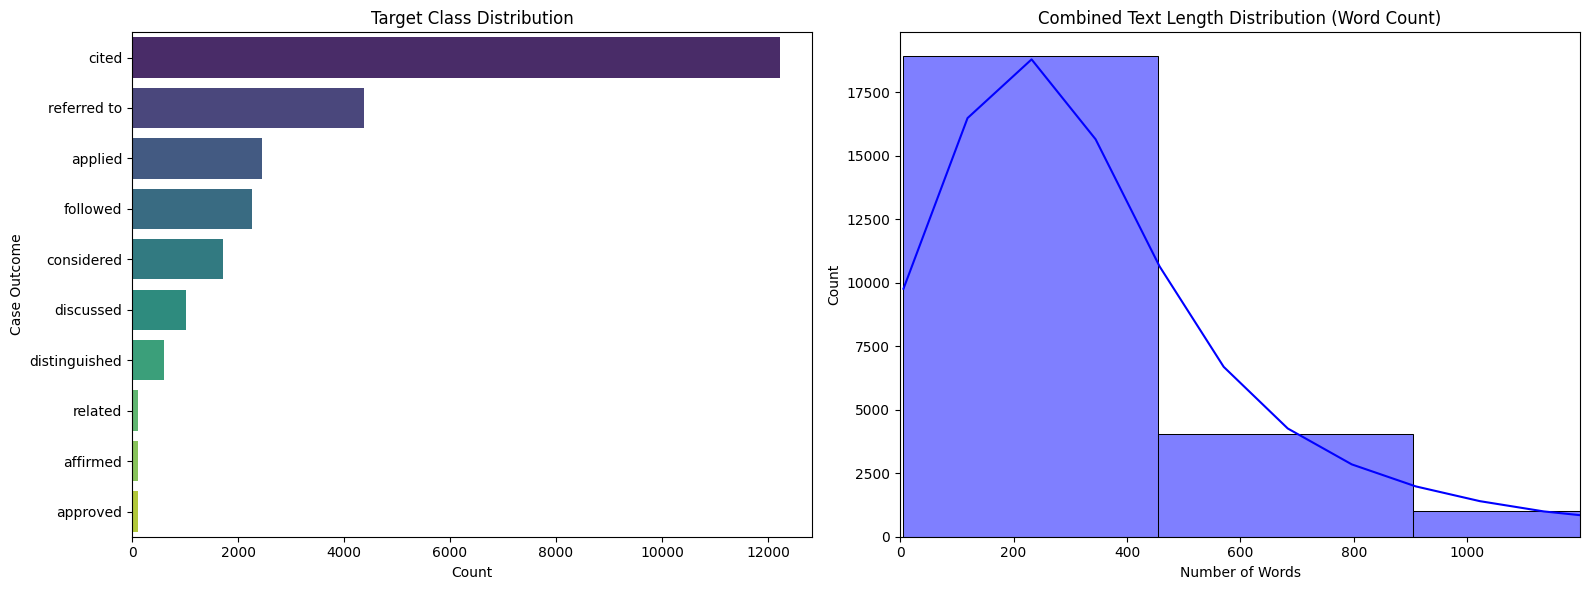

In [ ]:
# 2. Visualizations: Class distribution and text length distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(y=df_cleaned['case_outcome'], order=df_cleaned['case_outcome'].value_counts().index, ax=axes[0], palette='viridis')
axes[0].set_title("Target Class Distribution")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Case Outcome")

sns.histplot(df_cleaned['text_len'], bins=50, kde=True, ax=axes[1], color='blue')
axes[1].set_title("Combined Text Length Distribution (Word Count)")
axes[1].set_xlabel("Number of Words")
axes[1].set_xlim(0, df_cleaned['text_len'].quantile(0.95)) # Limit x-axis to 95th percentile for better visualization

plt.tight_layout()
plt.show()

## Case Study 9: Final Pipeline Integration and Artifact Export

### Objective
To package the optimized feature extractor and calibrated classifier into an atomic pipeline, evaluate it on the final split, and export it for downstream production services.

In [ ]:
# 3. Train final optimized pipeline (LinearSVC with TF-IDF, Calibrated for probabilities)
# Mild class balancing is applied in LinearSVC using 'balanced' class weights on training data only
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=60000, sublinear_tf=True, min_df=2)),
    ('clf', CalibratedClassifierCV(estimator=LinearSVC(C=0.5, class_weight='balanced', dual=False, random_state=42)))
])

print("Training the final optimized pipeline...")
best_pipeline.fit(X_train_c, y_train_c)

# Evaluate on untouched test set
y_pred_c = best_pipeline.predict(X_test_c)
y_prob_c = best_pipeline.predict_proba(X_test_c)

final_accuracy = accuracy_score(y_test_c, y_pred_c)
final_auc = roc_auc_score(y_test_bin_c, y_prob_c, multi_class='ovr', average='macro')

print(f"\nFinal Test Accuracy: {final_accuracy:.4f}")
print(f"Final Multiclass ROC-AUC (Macro OVR): {final_auc:.4f}")

# Save pipeline
joblib.dump(best_pipeline, 'best_legal_citation_pipeline.joblib')
print("Saved the pipeline successfully to 'best_legal_citation_pipeline.joblib'.")

Training the final optimized pipeline...

Final Test Accuracy: 0.6072
Final Multiclass ROC-AUC (Macro OVR): 0.8404
Saved the pipeline successfully to 'best_legal_citation_pipeline.joblib'.


## Case Study 10: Multi-Class ROC Evaluation

### Objective
To plot One-vs-Rest (OVR) ROC curves for each target class to visually confirm classification sensitivity and specificity.

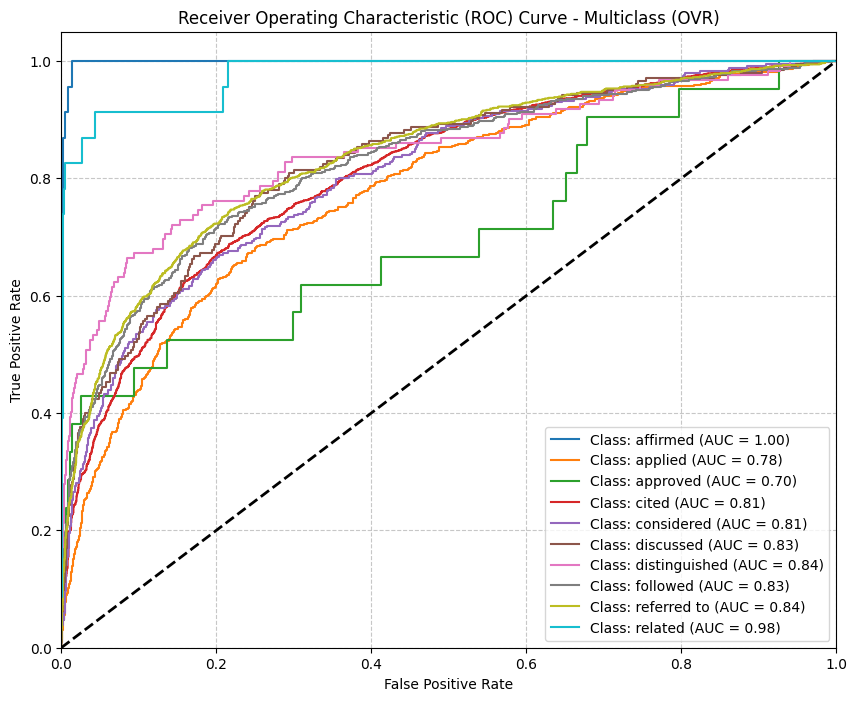

In [ ]:
from sklearn.metrics import roc_curve, auc

# 4. Plot Multi-class ROC curves for all classes
plt.figure(figsize=(10, 8))
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin_c[:, i], y_prob_c[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class: {classes[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Multiclass (OVR)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Case Study 11: Real-Time Inference Interface

### Objective
To create a clean, single-point inference function that replicates the preprocessing flow and outputs a predicted outcome accompanied by a statistical confidence score.

In [ ]:
import re
import html
import joblib

def predict_case_outcome(title, text, model_path='best_legal_citation_pipeline.joblib'):
    # 1. Load the pre-trained pipeline
    try:
        pipeline = joblib.load(model_path)
    except FileNotFoundError:
        return "Error: Pipeline file not found. Ensure 'best_legal_citation_pipeline.joblib' is saved in the directory."

    # 2. Replicate the preprocessing
    title_clean = title if isinstance(title, str) else ""
    text_clean = text if isinstance(text, str) else ""
    combined_text = title_clean + " " + text_clean

    # Clean text (HTML decode & Whitespace normalization)
    combined_text = html.unescape(combined_text)
    combined_text = re.sub(r'\s+', ' ', combined_text).strip()

    # 3. Predict outcome and associated probability
    prediction = pipeline.predict([combined_text])[0]
    probabilities = pipeline.predict_proba([combined_text])[0]

    # Map prediction to probability
    classes = pipeline.classes_
    pred_idx = list(classes).index(prediction)
    confidence = probabilities[pred_idx] * 100

    return prediction, confidence

# --- Demo Prediction Section ---
sample_title = "Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Ltd (No 2)"
sample_text = "Ordinarily that discretion will be exercised so that costs follow the event and are awarded on a party and party basis."

print("Running a test prediction with sample data...")
result, conf = predict_case_outcome(sample_title, sample_text)
print(f"Predicted Outcome: {result} (Confidence: {conf:.2f}%)")

Running a test prediction with sample data...
Predicted Outcome: cited (Confidence: 63.65%)
